### Defining State of Graph
- State defines store of messages of a graph

In [1]:
from dotenv import load_dotenv
load_dotenv()


True

In [2]:
import os
LANGSMITH_API_KEY = os.getenv("LANGSMITH_API_KEY")

In [3]:
from typing_extensions import TypedDict
class State(TypedDict):
    graph_info: str
    choice: str

In [4]:
def start_play(state:State):
    print("I will play right now")
    return {"graph_info": state["graph_info"] + "I will play right now"}

In [5]:
def play_cricket(state:State):
    print("I will play cricket")
    return {"graph_info": state["graph_info"] + " cricket"}

def play_football(state:State):
    print("I will play football")
    return {"graph_info": state["graph_info"] + " football"}

In [6]:
import random

def decision_node(state: State):
    choice = random.choice(["cricket", "football"])
    print(f"Decided to play {choice}")
    return {
        "graph_info": state["graph_info"] + f" Decided to play {choice}",
        "choice": choice
    }

In [9]:
from langgraph.graph import StateGraph, START, END

# Create the graph
graph = StateGraph(State)

# Add nodes
graph.add_node("start_play", start_play)
graph.add_node("decision", decision_node)
graph.add_node("play_cricket", play_cricket)
graph.add_node("play_football", play_football)

# Add edges
graph.add_edge(START, "start_play")
graph.add_edge("start_play", "decision")

# Conditional edge from decision to cricket or football
def router(state):
    return state["choice"]

graph.add_conditional_edges("decision", router, {
    "cricket": "play_cricket",
    "football": "play_football"
})

# Add edges to END
graph.add_edge("play_cricket", END)
graph.add_edge("play_football", END)

# Compile the graph
app = graph.compile()

# Invoke the graph with initial state
initial_state = {"graph_info": "Let's start: ", "choice": ""}
result = app.invoke(initial_state)
print("Final state:", result)

I will play right now
Decided to play football
I will play football
Final state: {'graph_info': "Let's start: I will play right now Decided to play football football", 'choice': 'football'}


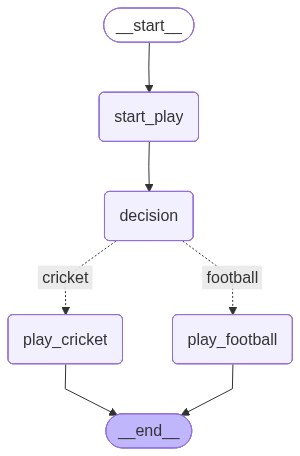

In [10]:
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Could not display graph: {e}")
    print("Make sure you have graphviz installed or use the mermaid string directly")